# What's That Critter - getting started with your data

Your data lives in an AWS S3 bucket. This notebook shows you how to connect, see what's there, read it **without downloading it**, and save your team's results.

**Your data:** `s3://ocean-hackathon-2026/data/critter/`  
Images packed in zip files, one per site (`campbell_river_images.zip`, `china_creek_images.zip`, `hartley_bay_images.zip`, ~100-220 MB each), plus a README: `CritterData_README.pdf`.

**⚠️ First, make your own copy:** this is the master copy, shared with everyone. Before running or editing it, **copy it to your home folder**: right-click the notebook in the file browser → **Copy**, go to your home folder (click the 📁 icon at the top of the file browser), then right-click → **Paste**. Open and run *that* copy.

**Before you start:** your team will be sent an **Access key ID** and a **Secret access key** (by direct message).
**Every team member** must run **Step 1** once, on their own hub account, and paste in the key.
After that you won't need the key again - in this notebook or any new notebooks you create.

**How to use this notebook:** run the cells in order, top to bottom - click into a cell and press **Shift+Enter**.
You don't need to change any code to get started.

## Where everything is

There are **two separate places** you'll use:

**1. The data bucket (`s3://ocean-hackathon-2026/`)** - cloud storage that holds the datasets and your team's saved results. You reach it from code, using the connection set up in Step 2.

```
ocean-hackathon-2026/
├── data/                  raw datasets - everyone can read, nobody can change
│   ├── bcferries/
│   ├── critter/      ← YOUR RAW DATA (read-only)
│   ├── elnino/
│   └── sound/
└── teams/                 team workspaces - each team can write only to its own
    ├── team-bcferries/
    ├── team-critter/  ← YOUR TEAM'S WORKSPACE (save here)
    ├── team-elnino/
    └── team-sound/
```
You can **read** every folder (including other teams' results), but you can only **save** to your own team folder.

**2. The hub file browser (left panel)** - your notebooks and small files.

```
your home folder/              private to you, ~10 GB - work on your notebooks here
└── shared-public/
    └── Victoria Ocean Hackathon 26/
        ├── BCFerries/
        ├── Critter/   ← YOUR TEAM'S HUB FOLDER
        ├── ElNino/
        └── Sound/
```
Your team's hub folder holds this **starter notebook** (the master copy - **copy it to your home folder before running or editing**) and is a place to share notebooks with teammates.

**Rule of thumb:**
- **Code and notebooks → GitHub** (work on them in your home folder). Hub access after the hackathon isn't guaranteed, and the data bucket and team keys are removed after the event - so anything you want to keep should be in GitHub.
- **Data, results, models, figures → your team folder in the bucket** (`TEAM_DIR`), so teammates can use them.

## Step 1 - Save your team's key (once per person)

**What it does:** stores your team's AWS key on *your* hub account, so your notebooks are allowed to read the hackathon data.

**Why:** the data is in a private storage bucket. Without the key, you'll get "access denied" errors.

**When to run it:** **once**, the first time you use the hub. It's saved in a hidden, private file in your home folder (`~/.aws/credentials`), **not** in this notebook. If you run it again later, it just says the key is already saved.

You'll be asked for the **Access key ID** and then the **Secret access key**. Nothing shows on screen while you paste - that's normal. Paste and press **Enter**.

In [1]:
# STEP 1 - ONE-TIME SETUP: save your team's key on your hub account.
# You'll be asked for the Access key ID and Secret access key your team was sent.
# Nothing shows on screen as you paste - that's normal. Just paste and press Enter.
# The key is saved privately in your own hub home folder (~/.aws), NOT in this notebook.
import configparser, getpass, os

cred_p = os.path.expanduser("~/.aws/credentials")
cfg_p  = os.path.expanduser("~/.aws/config")
os.makedirs(os.path.dirname(cred_p), exist_ok=True)

cred = configparser.ConfigParser(); cred.read(cred_p)
if "hack-team" in cred:
    print("A hack-team key is already saved - skipping. (To replace it, delete ~/.aws/credentials and rerun.)")
else:
    cred["hack-team"] = {
        "aws_access_key_id": getpass.getpass("Access key ID: ").strip(),
        "aws_secret_access_key": getpass.getpass("Secret access key: ").strip(),
    }
    with open(cred_p, "w") as f: cred.write(f)
    os.chmod(cred_p, 0o600)
    cfg = configparser.ConfigParser(); cfg.read(cfg_p)
    cfg["profile hack-team"] = {"region": "us-west-2"}
    with open(cfg_p, "w") as f: cfg.write(f)
    print("Saved! You won't need to do this again.")

Access key ID:  ········
Secret access key:  ········


Saved! You won't need to do this again.


## Step 2 - Connect to the data

**What it does:** opens a connection to the data bucket using your saved key, and works out which team you're on.

**Why:** every other cell in this notebook uses this connection (`fs`) and the two folder paths it sets up:
- `DATA_DIR` - your team's **raw data** (read-only - you can't change or delete it)
- `TEAM_DIR` - your team's **workspace** for results, models, figures (you *can* save files here)

**When to run it:** **every time** you open this notebook or restart the kernel - otherwise later cells will say `fs` or `DATA_DIR` is not defined.

**You should see:** `Connected as: team-...` followed by the two folder paths.

In [2]:
# STEP 2 - CONNECT TO THE DATA  (run every time you open the notebook)
import boto3, s3fs

DATA_FOLDER = "critter"       # your team's data folder - no need to change this

PROFILE = "hack-team"            # use the key you saved in Step 1 (the hub's own AWS login can't see this data)
BUCKET  = "ocean-hackathon-2026"
fs = s3fs.S3FileSystem(profile=PROFILE)

# Ask AWS which team this key belongs to, so you never have to type your team name
who = boto3.Session(profile_name=PROFILE).client("sts").get_caller_identity()["Arn"]
TEAM = who.split("/")[-1]                      # e.g. "team-sound"
TEAM_DIR = f"{BUCKET}/teams/{TEAM}"            # your team's workspace (you can save files here)
DATA_DIR = f"{BUCKET}/data/{DATA_FOLDER}"      # your raw data (read-only)

print("Connected as:", TEAM)
print("Raw data:    ", "s3://" + DATA_DIR)
print("Your outputs:", "s3://" + TEAM_DIR)

Connected as: team-critter
Raw data:     s3://ocean-hackathon-2026/data/critter
Your outputs: s3://ocean-hackathon-2026/teams/team-critter


## Starting your own notebook? Copy this to the top

You'll probably make your own notebooks for your project - that's encouraged! You **don't** need to repeat Step 1 (your key is already saved on your account).

**Why you need this cell anyway:** every new notebook starts with a blank slate. It doesn't know about the connection (`fs`) or the folder paths from *this* notebook. Without these lines, your code can't find the data, and AWS calls will fail with "access denied" - because the hub would use its own AWS login, which can't see the hackathon bucket.

Paste the cell below as the **first cell** of any new notebook and run it each time you open that notebook. (You don't need to run it here - Step 2 already did the same thing.)

When reading files with pandas or xarray, add `storage_options={"profile": "hack-team"}`, e.g.  
`pd.read_csv("s3://ocean-hackathon-2026/data/critter/FILE.csv", storage_options={"profile": "hack-team"})`

In [4]:
# Paste this at the top of your own notebooks
import s3fs
fs = s3fs.S3FileSystem(profile="hack-team")   # uses the key you saved in Step 1
BUCKET   = "ocean-hackathon-2026"
DATA_DIR = f"{BUCKET}/data/critter"          # your team's raw data (read-only)
TEAM_DIR = f"{BUCKET}/teams/team-critter"    # your team's workspace (save results here)

## Step 3 - What's in your data folder?

**What it does:** lists the files in your team's raw data folder, with their sizes.

**Why:** so you know what's available and what the file names are before you start reading data.

In [5]:
# STEP 3 - SEE WHAT'S IN YOUR DATA FOLDER
for info in fs.ls(DATA_DIR, detail=True):
    name = info["name"].split("/")[-1]
    if info["type"] == "directory":
        print(f'  [folder]   {name}/')
    elif name:
        print(f'{info["size"]/1e9:8.2f} GB   {name}')

    0.00 GB   CritterData_README.pdf
    0.17 GB   campbell_river_images.zip
    0.23 GB   china_creek_images.zip
    0.10 GB   hartley_bay_images.zip


## Read the README first
`CritterData_README.pdf` describes the images and sites. This copies it next to this notebook so you can open it from the file browser (PDFs are small, so this is fine):

In [6]:
fs.get(f"{DATA_DIR}/CritterData_README.pdf", "Critter_README.pdf")
print("Saved Critter_README.pdf next to this notebook - double-click it in the file browser")

Saved Critter_README.pdf next to this notebook - double-click it in the file browser


## Look inside a zip without downloading it
Python can open a zip file directly from S3 and read single images out of it.

In [54]:
import zipfile
zips = [p for p in fs.ls(DATA_DIR) if p.endswith(".zip")]
print("Zip files:", [z.split("/")[-1] for z in zips])

z = zipfile.ZipFile(fs.open(zips[0]))     # opens remotely - only reads what it needs
images = [n for n in z.namelist() if n.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))]
print(len(images), "images in", zips[0].split("/")[-1])
images[:10]

Zip files: ['campbell_river_images.zip', 'china_creek_images.zip', 'hartley_bay_images.zip']
1177 images in campbell_river_images.zip


['campbell_river_images/AXISCAMACCC8E891288_20190104T160007.000Z_t0145.00.jpg',
 'campbell_river_images/AXISCAMACCC8E891288_20190104T200009.000Z_t0011.00.jpg',
 'campbell_river_images/AXISCAMACCC8E891288_20190107T010008.000Z_t0130.00.jpg',
 'campbell_river_images/AXISCAMACCC8E891288_20190107T060010.000Z_t0115.00.jpg',
 'campbell_river_images/AXISCAMACCC8E891288_20190107T060010.000Z_t0159.00.jpg',
 'campbell_river_images/AXISCAMACCC8E891288_20190107T060010.000Z_t0194.00.jpg',
 'campbell_river_images/AXISCAMACCC8E891288_20190107T060010.000Z_t0211.00.jpg',
 'campbell_river_images/AXISCAMACCC8E891288_20190107T070005.000Z_t0153.00.jpg',
 'campbell_river_images/AXISCAMACCC8E891288_20190110T210009.000Z_t0259.00.jpg',
 'campbell_river_images/AXISCAMACCC8E891288_20190111T160008.000Z_t0094.00.jpg']

campbell_river_images/AXISCAMACCC8E891288_20190104T160007.000Z_t0145.00.jpg (1024, 768)


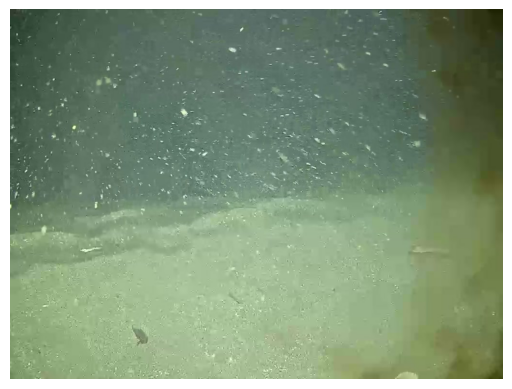

In [55]:
# Show one image
import io
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(io.BytesIO(z.read(images[150])))
print(images[0], img.size)
plt.imshow(img); plt.axis("off"); plt.show()

**Tip:** these zips are small (~100-220 MB). If it's easier, you can copy one into your home folder and unzip it there:

```python
fs.get(zips[0], "site.zip")
!unzip -q site.zip -d site_images
```

## Save your work

**What it does:** saves a small example file to your team's workspace (`TEAM_DIR`) in the bucket, then lists that folder.

**Why:** your hub home folder is small (about 10 GB) and is personal. Save results, models and figures you want to keep - or share with your team - to `TEAM_DIR`. Everyone on your team can see them.

Replace the example with your own outputs.

In [11]:
# SAVE YOUR WORK to your team folder (the only place you can write).
# Example: save a small results table. Replace with your own outputs.
import pandas as pd
results = pd.DataFrame({"note": ["hello from " + TEAM]})
with fs.open(f"{TEAM_DIR}/example_results.csv", "w") as f:
    results.to_csv(f, index=False)

print(fs.ls(TEAM_DIR))

# Read it back later with:
# pd.read_csv(f"s3://{TEAM_DIR}/example_results.csv", storage_options={"profile": PROFILE})
#
# For bigger files you made on the hub (models, figures): fs.put("local_file.pt", f"{TEAM_DIR}/local_file.pt")

['ocean-hackathon-2026/teams/team-critter/', 'ocean-hackathon-2026/teams/team-critter/example_results.csv']


## Working together as a team

**Important:** Jupyter notebooks are **not** like Google Docs. If two people edit the same notebook at the same time, they don't see each other's changes - whoever saves last wins, and the other person's work is lost.

### Recommended: GitHub
**Store your team's code in a GitHub repository.** You already have a GitHub account (it's how you log in to the hub). Why it's worth it:
- **Work together without overwriting each other** - everyone edits their own copy and merges changes.
- **History** - undo mistakes and see who changed what.
- **Share your project** - one link for judges, mentors and (for the winners) the December finale.
- **Keep your work** - hub access after the hackathon isn't guaranteed, and the data bucket and team keys are removed after the event. GitHub is where your project lives on.

**How (about 10 minutes):**
1. One person creates a repo on github.com and adds teammates as collaborators. Choose **Private** if you're unsure.
2. Everyone clones it into their **own home folder** on the hub (Terminal: `git clone <repo URL>`), or use the **Git** tab on the left.
3. Work in your own notebooks, then **commit** and **push**. Teammates **pull** to get your changes.
4. Tip: give each person their own notebook - two people editing the *same* notebook causes painful merge conflicts.

**⚠️ Never put these in GitHub:**
- **Your AWS key** (or anything from `~/.aws/`).
- **Data files** - datasets, zips, model checkpoints, big outputs. GitHub is for code; data stays in the bucket (`DATA_DIR` / `TEAM_DIR`). Large files will also be rejected by GitHub.
- Tip: before committing, use **Kernel → Restart Kernel and Clear Outputs** so big plots and printed data aren't saved inside your notebooks.

Pushing from the hub may ask you to sign in to GitHub with a personal access token. If nobody on your team has used Git before, ask your data coach to help set it up in the first 15 minutes.

GitHub is **recommended, not required** - if it's not for your team, use the option below.

### No Git experience? That's fine - do this instead
- **One notebook per person**, named with your name, e.g. `alex_spectrograms.ipynb`.
- Put them in your team's hub folder (`shared-public/Victoria Ocean Hackathon 26/<your team>/`) so teammates can **open and read** them - but **only edit your own**.
- Before the hackathon ends, **download your notebooks** (right-click → Download) or get them into GitHub, in case hub access ends.
- To use a teammate's code, **copy** their notebook to your home folder first.

### Either way: share *data* through your team workspace
Save results, processed data, models and figures to `TEAM_DIR` (your team's folder in the bucket). Every teammate can read them from there, no matter which notebook they're in.

## Rules and tips

- **Work on the hub only. Don't download the datasets to your laptop** - it costs real money and the files are big.
- **Don't copy whole datasets into your hub home folder** (limit is about 10 GB). Read only what you need, straight from S3.
- **In your own new notebooks**, connect with `s3fs.S3FileSystem(profile="hack-team")` (or `storage_options={"profile": "hack-team"}` in pandas/xarray). You don't need to enter the key again.
- **Save outputs to your team folder** (`TEAM_DIR`). You can read everyone's data, but you can only write to your own team folder. You can't change or delete the raw data.
- **Collaborating?** Don't edit the same notebook at the same time as a teammate - see *Working together as a team* above.
- **Never paste your key into a notebook, GitHub, Slack channels or `shared-public`.**
- **Copy this notebook to your own home folder before editing** - files in `shared-public` can be edited by anyone, so the master copy must stay untouched for everyone else.
- **When you're done:** File → Hub Control Panel → **Stop My Server**, then close the tab. Servers stop by themselves after ~90 minutes idle.
- If the bottom bar says **kernel disconnected**, your code isn't running - restart the kernel or reopen the notebook.
- `pip install` only lasts for the current session - put `%pip install <package>` at the top of your notebook.
- Stuck? Ask your data coach.